In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import (
    load_iris, fetch_california_housing, make_classification
)
from sklearn.model_selection import (
    train_test_split, cross_val_score, KFold
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import (
    DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
)
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, classification_report,
    mean_squared_error, r2_score, confusion_matrix
)

np.random.seed(42)
print("✅ All dependencies successfully loaded!")

✅ All dependencies successfully loaded!


In [8]:
# Activity 1:
p = np.array([2.0, 3.0])
q = np.array([5.0, 7.0])

# Euclidean distance
euclidean_dist = np.linalg.norm(p - q)
# Manhattan distance
manhattan_dist = np.sum(np.abs(p - q))

print(f"Point p: {p}, Point q: {q}")
print(f"Euclidean Distance: {euclidean_dist:.4f}")
print(f"Manhattan Distance: {manhattan_dist:.4f}")

Point p: [2. 3.], Point q: [5. 7.]
Euclidean Distance: 5.0000
Manhattan Distance: 7.0000


Best k found via 5-Fold CV: k = 5 with accuracy 0.9667


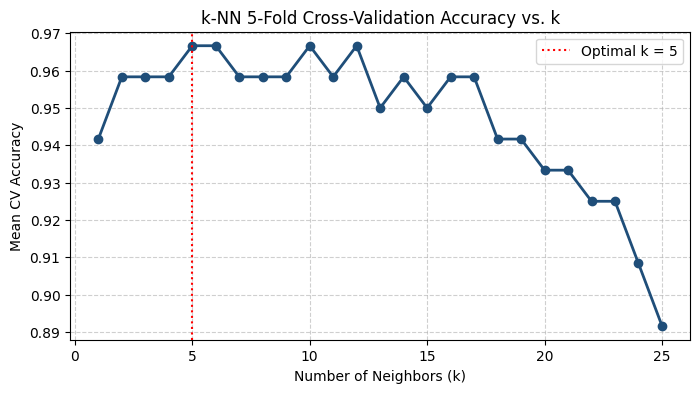

In [5]:
#Activity 2:
# Load Iris dataset for 3-class classification
iris = load_iris()
X, y = iris.data, iris.target

# Split into 80% train and 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Evaluate k from 1 to 25 using 5-Fold Cross-Validation
k_values = range(1, 26)
cv_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(
        knn, X_train_scaled, y_train, cv=5, scoring="accuracy"
    )
    cv_scores.append(scores.mean())

# Find best k
best_k = k_values[np.argmax(cv_scores)]
print(
    f"Best k found via 5-Fold CV: k = {best_k} "
    f"with accuracy {max(cv_scores):.4f}"
)

# Plot Cross-Validation Accuracy vs. k
plt.figure(figsize=(8, 4))
plt.plot(k_values, cv_scores, marker="o", color="#1F4E79", linewidth=2)
plt.title("k-NN 5-Fold Cross-Validation Accuracy vs. k")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Mean CV Accuracy")
plt.grid(True, linestyle="--", alpha=0.6)
plt.axvline(
    best_k, color="red", linestyle=":", label=f"Optimal k = {best_k}"
)
plt.legend()
plt.show()

Decision Tree -> Test Accuracy: 0.7840
Random Forest (100 trees) -> Test Accuracy: 0.8160


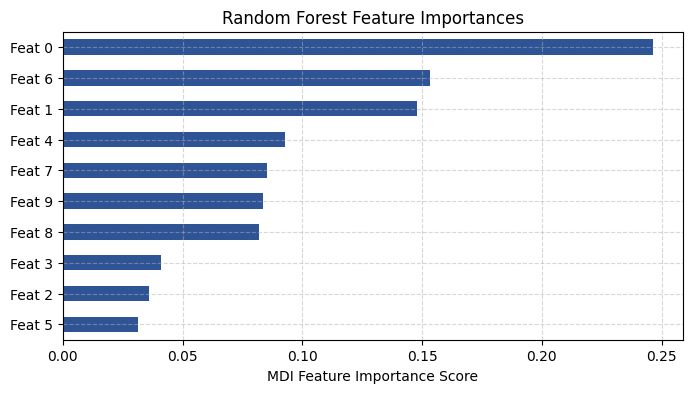

In [6]:
#activity 3
# Generate a noisy synthetic dataset
X_syn, y_syn = make_classification(
    n_samples=500,
    n_features=10,
    n_informative=5,
    n_redundant=2,
    flip_y=0.1,
    random_state=42
)

X_syn_tr, X_syn_te, y_syn_tr, y_syn_te = train_test_split(
    X_syn, y_syn, test_size=0.25, random_state=42
)

# Train Single Tree vs. Random Forest (100 trees)
dt = DecisionTreeClassifier(random_state=42)
rf = RandomForestClassifier(
    n_estimators=100,
    max_features="sqrt",
    random_state=42
)

dt.fit(X_syn_tr, y_syn_tr)
rf.fit(X_syn_tr, y_syn_tr)

print(
    f"Decision Tree -> Test Accuracy: "
    f"{dt.score(X_syn_te, y_syn_te):.4f}"
)
print(
    f"Random Forest (100 trees) -> Test Accuracy: "
    f"{rf.score(X_syn_te, y_syn_te):.4f}"
)

# Plot Feature Importances from Random Forest
plt.figure(figsize=(8, 4))

feat_importances = pd.Series(
    rf.feature_importances_,
    index=[f"Feat {i}" for i in range(10)]
)

feat_importances.sort_values().plot(kind="barh", color="#2F5496")
plt.title("Random Forest Feature Importances")
plt.xlabel("MDI Feature Importance Score")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

Compare a single Decision Tree against a Random Forest on a noisy
synthetic dataset and inspect feature importance.  

The Decision Tree achieved 78.40% test accuracy, while Random Forest achieved 81.60%. Random Forest performed better by 3.2 percentage points. Combining multiple trees helps reduce variance compared with a single tree. Feat 0 had the highest importance, followed by Feat 6 and Feat 1, while Feat 5 had the lowest importance.

In [7]:
import pandas as pd
import os

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 1. Load California Housing data from Colab sample files
train_path = "/content/sample_data/california_housing_train.csv"
test_path = "/content/sample_data/california_housing_test.csv"

if os.path.exists(train_path) and os.path.exists(test_path):
    df_train = pd.read_csv(train_path)
    df_test = pd.read_csv(test_path)
    df = pd.concat([df_train, df_test], ignore_index=True)

    df = df.rename(columns={
        "median_house_value": "MedHouseVal",
        "median_income": "MedInc",
        "total_rooms": "AveRooms"
    })

    # Express house values in units of $100,000
    df["MedHouseVal"] = df["MedHouseVal"] / 100000.0

    # Calculate average rooms per household
    df["AveRooms"] = df["AveRooms"] / df["households"]
else:
    raise FileNotFoundError(
        "Colab sample data not found. Please verify /content/sample_data/."
    )

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

# 2. Select features and target
X = df[["MedInc", "AveRooms"]]
y = df["MedHouseVal"]

# 3. Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 4. Create KNN regressor
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsRegressor(n_neighbors=10)
)

# 5. Create Random Forest regressor
rf_model = RandomForestRegressor(
    n_estimators=50,
    random_state=42
)

# 6. Train both models
knn_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

# 7. Make predictions
knn_predictions = knn_model.predict(X_test)
rf_predictions = rf_model.predict(X_test)

# 8. Calculate evaluation metrics
knn_mse = mean_squared_error(y_test, knn_predictions)
knn_r2 = r2_score(y_test, knn_predictions)

rf_mse = mean_squared_error(y_test, rf_predictions)
rf_r2 = r2_score(y_test, rf_predictions)

# 9. Display results
print("\nMODEL PERFORMANCE COMPARISON")

print("\nK-Nearest Neighbors Regression")
print(f"Test MSE: {knn_mse:.4f}")
print(f"Test R²:  {knn_r2:.4f}")

print("\nRandom Forest Regression")
print(f"Test MSE: {rf_mse:.4f}")
print(f"Test R²:  {rf_r2:.4f}")

Dataset shape: (20000, 9)

First 5 rows:
   longitude  latitude  housing_median_age   AveRooms  total_bedrooms  \
0    -114.31     34.19                15.0  11.889831          1283.0   
1    -114.47     34.40                19.0  16.522678          1901.0   
2    -114.56     33.69                17.0   6.153846           174.0   
3    -114.57     33.64                14.0   6.641593           337.0   
4    -114.57     33.57                20.0   5.549618           326.0   

   population  households  MedInc  MedHouseVal  
0      1015.0       472.0  1.4936        0.669  
1      1129.0       463.0  1.8200        0.801  
2       333.0       117.0  1.6509        0.857  
3       515.0       226.0  3.1917        0.734  
4       624.0       262.0  1.9250        0.655  

Training samples: 16000
Testing samples: 4000

MODEL PERFORMANCE COMPARISON

K-Nearest Neighbors Regression
Test MSE: 0.6636
Test R²:  0.5167

Random Forest Regression
Test MSE: 0.7217
Test R²:  0.4744


Which model has the lower Test MSE?
KNN Regression has the lower Test MSE of 0.6636.

What does this tell you about its prediction performance?
KNN has a smaller average squared prediction error, meaning its predictions are closer to the actual house values under this metric.

Which model has the higher Test R² score?
KNN Regression has the higher Test R² score of 0.5167.

What does this tell you about the model?
KNN explains approximately 51.67% of the variation in house values in the test dataset, compared with 47.44% for Random Forest. R² is not classification accuracy.

Based on both MSE and R², which model performs better on the test dataset?
KNN Regression performs better, because it has both a lower MSE and a higher R².

| Model | Test MSE | Test R² |
|---|---:|---:|
| KNN Regression | 0.6636 | 0.5167 |
| Random Forest Regression | 0.7217 | 0.4744 |